# Chess Direct QA results
Set `EXP_DIR` to an experiment directory. The notebook uses pandas, matplotlib, and seaborn, matching `plot_minimal.ipynb`. Only completed puzzles are scored. Partial runs can have unequal bucket counts; finish the run for balanced comparisons.


In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

repo_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "core").is_dir())
EXP_DIR = repo_root / "exp" / "chess_comparison"
FIGURE_DIR = EXP_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="colorblind")
BUCKETS = ["Low", "Medium", "High"]
paths = sorted((EXP_DIR / "direct_qa").glob("*/puzzles.csv"))
if not paths:
    raise FileNotFoundError(f"No puzzle results in {EXP_DIR}")
raw = pd.concat([pd.read_csv(path, keep_default_na=False, dtype={"puzzleId": str}) for path in paths], ignore_index=True)
df = raw[raw["complete"].astype(str).str.lower().eq("true")].copy()
if df.empty:
    print("No completed puzzles yet; skip the charts and inspect saved requests below.")
df["correct"] = df["correct"].astype(str).str.lower().eq("true").astype(int)
df["rating"] = pd.to_numeric(df["rating"])
models = list(df["model"].unique())
colors = dict(zip(models, sns.color_palette("colorblind", n_colors=len(models))))
summary = df.groupby("model")["correct"].agg(success_rate="mean", puzzles="size")
PUZZLES_PER_MODEL = summary["puzzles"].max()
display(summary)
display(df.groupby(["model", "rating_bucket"])["correct"].size().unstack().reindex(columns=BUCKETS))


,success_rate,puzzles
model,,
claude-haiku-5-5,0.486667,150
claude-sonnet-5-5,0.406667,150
gpt-5-mini,0.193333,150
gpt-6-luna,0.253333,150
gpt-6.1-sol,0.720000,150
openai/gpt-oss-120b,0.333333,150
openai/gpt-oss-20b,0.083333,120


rating_bucket,Low,Medium,High
model,,,
claude-haiku-5-5,50,50,50
claude-sonnet-5-5,50,50,50
gpt-5-mini,50,50,50
gpt-6-luna,50,50,50
gpt-6.1-sol,50,50,50
openai/gpt-oss-120b,50,50,50
openai/gpt-oss-20b,41,41,38


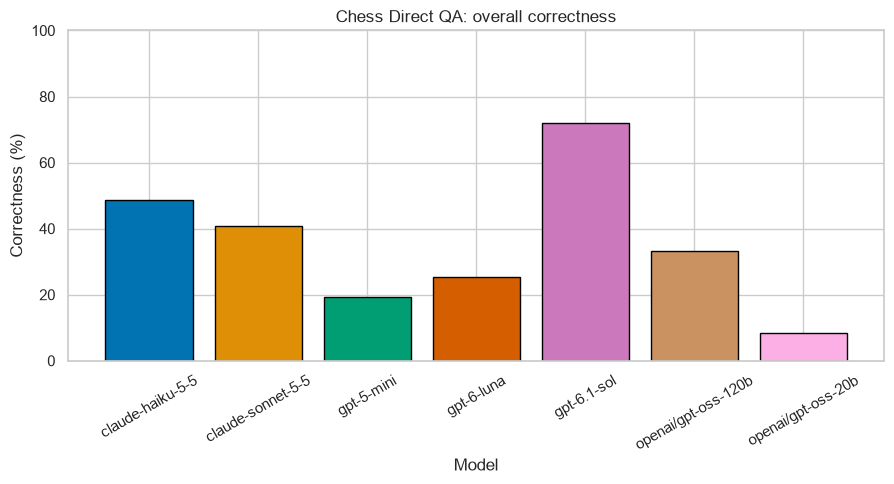

In [2]:
fig, ax = plt.subplots(figsize=(max(6, len(models) * 1.3), 5))
overall = summary.reindex(models)
ax.bar(models, overall["success_rate"] * 100, color=[colors[m] for m in models], edgecolor="black")
ax.set(ylabel="Correctness (%)", xlabel="Model", ylim=(0, 100), title="Chess Direct QA: overall correctness")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "overall_correctness.png", dpi=300, bbox_inches="tight")
plt.show()


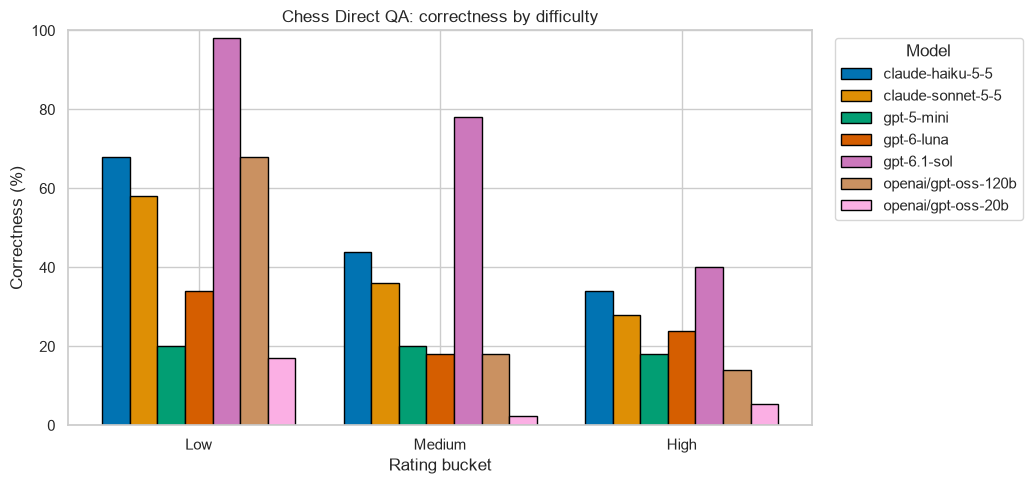

In [3]:
rates = df.groupby(["model", "rating_bucket"])["correct"].mean().unstack().reindex(index=models, columns=BUCKETS)
fig, ax = plt.subplots(figsize=(max(7, len(models) * 1.5), 5))
x = np.arange(len(BUCKETS))
width = 0.8 / len(models)
for i, model in enumerate(models):
    ax.bar(x - 0.4 + width * (i + 0.5), rates.loc[model] * 100, width=width,
           label=model, color=colors[model], edgecolor="black")
ax.set(xticks=x, xticklabels=BUCKETS, ylabel="Correctness (%)", xlabel="Rating bucket",
       ylim=(0, 100), title="Chess Direct QA: correctness by difficulty")
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "bucket_correctness.png", dpi=300, bbox_inches="tight")
plt.show()


## Success versus puzzle rating
Fit ordinary least squares to per-puzzle binary correctness, giving every puzzle equal weight. Points show the observed success rate in 100-rating intervals; each line is the model's linear regression fit. A linear fit is descriptive and may predict outside 0–100%, so the axis is not clipped.


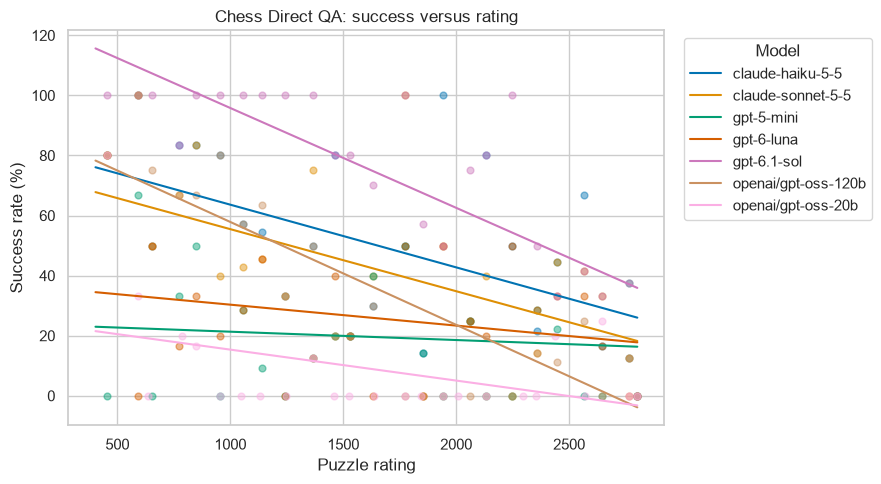

,model,slope,intercept,puzzles
0,claude-haiku-5-5,-0.000209,0.844806,150
1,claude-sonnet-5-5,-0.000207,0.761195,150
2,gpt-5-mini,-0.000028,0.240881,150
3,gpt-6-luna,-0.000070,0.372864,150
4,gpt-6.1-sol,-0.000332,1.290326,150
5,openai/gpt-oss-120b,-0.000342,0.920967,150
6,openai/gpt-oss-20b,-0.000103,0.256576,120


In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
regressions = []
for model in models:
    subset = df[df["model"] == model].copy()
    subset["rating_interval"] = (subset["rating"] // 100) * 100
    observed = subset.groupby("rating_interval").agg(rating=("rating", "mean"), success_rate=("correct", "mean"))
    ax.scatter(observed["rating"], observed["success_rate"] * 100, color=colors[model], alpha=0.45, s=24)
    if subset["rating"].nunique() < 2:
        print(f"Skipping regression for {model}: need two distinct ratings")
        continue
    slope, intercept = np.polyfit(subset["rating"], subset["correct"], 1)
    x = np.linspace(subset["rating"].min(), subset["rating"].max(), 200)
    ax.plot(x, (slope * x + intercept) * 100, color=colors[model], label=model)
    regressions.append(dict(model=model, slope=slope, intercept=intercept, puzzles=len(subset)))
ax.set(xlabel="Puzzle rating", ylabel="Success rate (%)", title="Chess Direct QA: success versus rating")
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "rating_regression.png", dpi=300, bbox_inches="tight")
plt.show()
display(pd.DataFrame(regressions))


## Inspect a single puzzle request
Run the data-loading cell above, then these cells. Set `MODEL` and `PUZZLE_ID` to a saved request (the defaults select the first row). The report includes the original board, expected SAN move, full saved model output, and numbered SAN candidate lines with tool results. Expand **Arguments and result** for raw arguments and the returned FEN. Incomplete requests can also be inspected; the report displays only reasoning/output saved by the API.

Token usage shows input, output, and their total across the puzzle’s API calls. Output budgets are loaded from `EXP_DIR/chess_run.json`, with both the per-call limit and the maximum across all permitted calls. Missing usage or run settings are shown as unavailable.


In [5]:
import json
import numpy as np
from html import escape
from pathlib import Path

import chess
import chess.svg
from IPython.display import HTML, display


def _candidate_line(fen, arguments):
    """Translate tool arguments into numbered SAN, stopping at an illegal move."""
    if isinstance(arguments, str):
        try:
            arguments = json.loads(arguments)
        except (ValueError, TypeError):
            return f"Malformed arguments: {arguments}"
    tokens = arguments.get("moves") if isinstance(arguments, dict) else None
    if not isinstance(tokens, list) or not tokens:
        return f"Invalid arguments: {json.dumps(arguments, ensure_ascii=False)}"
    board = chess.Board(fen)
    moves, illegal = [], None
    for token in tokens:
        try:
            if not isinstance(token, str):
                raise ValueError("Move must be a string")
            try:
                move = board.parse_san(token)
            except ValueError:
                move = board.parse_uci(token)
            if move not in board.legal_moves:
                raise ValueError("Illegal move")
            board.push(move)
            moves.append(move)
        except ValueError:
            illegal = str(token)
            break
    line = chess.Board(fen).variation_san(moves) if moves else ""
    if illegal is not None:
        line += f" [illegal move: {illegal}]"
    return line.strip()


def puzzle_html(row, settings=None):
    """Build a self-contained HTML report from one puzzles.csv row."""
    def value(key, default=""):
        item = row.get(key, default)
        return default if item is None or (not isinstance(item, (dict, list)) and pd.isna(item)) else item

    def text(item):
        return escape(str(item))

    fen = str(value("FEN"))
    board = chess.Board(fen)
    solution = str(value("moves")).split()
    expected = board.san(board.parse_uci(solution[0])) if solution else value("expected_move", "Unavailable")
    complete = str(value("complete", False)).lower() == "true"
    correct = str(value("correct", False)).lower() == "true"
    status = "Correct" if complete and correct else "Incorrect" if complete else "Incomplete"
    diagram = chess.svg.board(board, orientation=board.turn, size=380,
                              check=board.king(board.turn) if board.is_check() else None)

    trace = value("tool_trace", "[]")
    trace_error = ""
    try:
        trace = json.loads(trace) if isinstance(trace, str) else trace
        if not isinstance(trace, list):
            raise ValueError("Expected a list of trace entries")
    except (ValueError, TypeError) as exc:
        trace_error = f"Could not read saved tool trace: {exc}"
        trace = []

    # Read the recorded run limits rather than assuming today's defaults.
    if settings is None:
        manifest = Path(EXP_DIR) / "chess_run.json" if "EXP_DIR" in globals() else None
        try:
            settings = json.loads(manifest.read_text()) if manifest and manifest.exists() else {}
        except (OSError, ValueError):
            settings = {}

    def count(item):
        try:
            number = float(item)
            return number if np.isfinite(number) and number >= 0 else None
        except (ValueError, TypeError):
            return None

    def formatted(number):
        return f"{number:,.0f}" if number is not None else "Unavailable"

    responses = [entry for entry in trace if isinstance(entry, dict) and "completion" in entry]

    def spent(key):
        recorded = count(value(key, None))
        if recorded is not None:
            return recorded
        counts = [count(entry.get(key)) for entry in responses]
        return sum(counts) if counts and all(n is not None for n in counts) else None

    input_spent, output_spent = spent("input_tokens"), spent("output_tokens")
    total_spent = input_spent + output_spent if input_spent is not None and output_spent is not None else None
    per_call_budget = count(settings.get("max_tokens"))
    tool_round_budget = count(settings.get("max_tool_rounds"))
    use_tools = settings.get("use_tools", True)
    max_calls = 1 if not use_tools else tool_round_budget + 1 if tool_round_budget is not None else None
    puzzle_budget = per_call_budget * max_calls if per_call_budget is not None and max_calls is not None else None
    api_calls = count(value("api_calls", None))
    if api_calls is None and responses:
        api_calls = len(responses)

    # Responses contain requests; separate trace entries contain executed results.
    # Match by call ID so each tool call appears exactly once, including pending calls.
    calls, results = {}, {}
    for entry in trace:
        if not isinstance(entry, dict):
            continue
        for call in entry.get("tool_calls", []) or []:
            calls[call["id"]] = call
        if "tool_call" in entry:
            call = entry["tool_call"]
            calls[call["id"]] = call
            results[call["id"]] = entry.get("result", {})

    tool_rows = []
    for number, (call_id, call) in enumerate(calls.items(), start=1):
        function = call.get("function", {})
        arguments = function.get("arguments", "{}")
        line = _candidate_line(fen, arguments) if function.get("name") == "validate_move_sequence" else str(arguments)
        result = results.get(call_id)
        if result is None:
            outcome = "No saved result (call may not have executed)."
        elif result.get("error"):
            outcome = f"Error: {result['error']}"
        elif "board" in result:
            outcome = "Unicode board:"
        elif result.get("legal") is True:
            outcome = "Legal sequence."
        elif result.get("legal") is False:
            outcome = f"Illegal sequence; first illegal move: {result.get('first_illegal_move')}"
        else:
            outcome = "No legality result available."
        outcome_html = text(outcome)
        if result is not None and "board" in result:
            outcome_html += f"<pre style='white-space:pre;font-family:monospace'>{text(result['board'])}</pre>"
        details = dict(arguments=arguments, result=result)
        tool_rows.append(f"""<tr><td>{number}</td><td><code>{text(function.get('name', 'Unknown tool'))}</code>
          <br><small>{text(call_id)}</small></td><td>{text(line)}</td><td>{outcome_html}
          <details><summary>Arguments and result</summary><pre>{text(json.dumps(details, indent=2, ensure_ascii=False))}</pre></details></td></tr>""")
    tools = ("<div style='overflow-x:auto'><table><thead><tr><th>#</th><th>Tool</th><th>Arguments / candidate line (SAN)</th><th>Result</th></tr></thead><tbody>"
             + "".join(tool_rows) + "</tbody></table></div>") if tool_rows else "<p>No saved tool calls.</p>"
    def tool_count(field, name, illegal_only=False):
        recorded = count(value(field, None))
        if recorded is not None:
            return recorded
        return sum(call.get("function", {}).get("name") == name
                   and (not illegal_only or results[call_id].get("legal") is False)
                   for call_id, call in calls.items() if call_id in results)

    validation_calls = tool_count("validate_move_sequence_calls", "validate_move_sequence")
    board_calls = tool_count("display_board_unicode_calls", "display_board_unicode")
    illegal_calls = tool_count("validate_move_sequence_illegal_calls", "validate_move_sequence", illegal_only=True)
    side = "White" if board.turn == chess.WHITE else "Black"
    error = f"<p><strong>Request error:</strong> {text(value('error'))}</p>" if value("error") else ""
    return f"""<section style="font-family:system-ui,sans-serif;line-height:1.5;max-width:1150px">
      <h2>Puzzle {text(value('puzzleId'))}</h2>
      <div style="display:flex;flex-wrap:wrap;gap:28px;align-items:flex-start">
        <div style="width:380px;max-width:100%">{diagram}<p>{side} to move · board shown from {side.lower()}'s side</p></div>
        <div><table style="text-align:left">
          <tr><th>Model</th><td>{text(value('model'))}</td></tr>
          <tr><th>Puzzle ID</th><td>{text(value('puzzleId'))}</td></tr>
          <tr><th>Rating</th><td>{text(value('rating'))} · {text(value('rating_bucket'))}</td></tr>
          <tr><th>Correct move (SAN)</th><td><strong>{text(expected)}</strong></td></tr>
          <tr><th>Model's final move</th><td>{text(value('final_move', 'Unavailable'))}</td></tr>
          <tr><th>Result</th><td>{status}</td></tr>
          <tr><th>Input tokens spent</th><td>{formatted(input_spent)}</td></tr>
          <tr><th>Output tokens spent</th><td>{formatted(output_spent)}</td></tr>
          <tr><th>Total tokens spent</th><td>{formatted(total_spent)}</td></tr>
          <tr><th>Output budget per API call</th><td>{formatted(per_call_budget)}</td></tr>
          <tr><th>Maximum output budget per puzzle</th><td>{formatted(puzzle_budget)}</td></tr>
          <tr><th>API calls used / maximum</th><td>{formatted(api_calls)} / {formatted(max_calls)}</td></tr>
          <tr><th>Move validation calls</th><td>{formatted(validation_calls)}</td></tr>
          <tr><th>Illegal validation sequences</th><td>{formatted(illegal_calls)}</td></tr>
          <tr><th>Unicode board calls</th><td>{formatted(board_calls)}</td></tr>
        </table>
        <p style="max-width:440px"><small>Usage sums all saved API calls for this puzzle.
        Budgets limit output tokens, including provider reasoning tokens where applicable;
        input tokens are additional. The puzzle maximum allows all configured tool rounds
        plus one final answer call; with tools disabled, there is one call.</small></p>{error}</div>
      </div>
      <details><summary>Position FEN</summary><pre style="white-space:pre-wrap;overflow-wrap:anywhere">{text(fen)}</pre></details>
      <h3>Model output</h3>
      <pre style="white-space:pre-wrap;overflow-wrap:anywhere;border:1px solid #999;border-radius:6px;padding:16px;max-height:650px;overflow:auto">{text(value('model_response', 'No saved output.'))}</pre>
      <h3>Tool calls</h3>
      <p>Each candidate line starts from the original puzzle position. UCI moves are translated to SAN where legal.</p>
      <p>{text(trace_error)}</p>{tools}
    </section>"""


def display_puzzle(puzzle_id=None, model=None, frame=None, settings=None):
    """Display a saved request; omit both selectors to inspect the first row."""
    frame = raw if frame is None else frame
    selected = frame
    if model is not None:
        selected = selected[selected["model"] == model]
    if puzzle_id is not None:
        selected = selected[selected["puzzleId"].astype(str) == str(puzzle_id)]
    if selected.empty:
        raise ValueError(f"No saved request for model={model!r}, puzzle_id={puzzle_id!r}")
    if len(selected) > 1 and puzzle_id is not None and model is None:
        raise ValueError(f"Specify model as well; this puzzle has results for {selected['model'].unique().tolist()}")
    display(HTML(puzzle_html(selected.iloc[0], settings=settings)))


In [11]:
#Display first 5 puzzles for each model.
for i in range(0, len(raw), PUZZLES_PER_MODEL):
    display(raw[["model", "puzzleId", "rating", "rating_bucket", "complete", "correct"]].loc[i:i+5])
idx=5
MODEL = raw.iloc[idx]["model"]
PUZZLE_ID = raw[raw["model"] == MODEL].iloc[idx]["puzzleId"]
# Example: display_puzzle(puzzle_id="00JET", model="your-model-api-id")
display_puzzle(puzzle_id=PUZZLE_ID, model=MODEL)


,model,puzzleId,rating,rating_bucket,complete,correct
0,claude-haiku-5-5,02im6,2356,High,True,True
1,claude-haiku-5-5,019wq,2110,Medium,True,False
2,claude-haiku-5-5,04XTY,2328,High,True,False
3,claude-haiku-5-5,00FHX,473,Low,True,True
4,claude-haiku-5-5,00baZ,812,Low,True,True
5,claude-haiku-5-5,01EFz,761,Low,True,True


,model,puzzleId,rating,rating_bucket,complete,correct
150,claude-sonnet-5-5,02im6,2356,High,True,True
151,claude-sonnet-5-5,019wq,2110,Medium,True,False
152,claude-sonnet-5-5,04XTY,2328,High,True,False
153,claude-sonnet-5-5,00FHX,473,Low,True,True
154,claude-sonnet-5-5,00baZ,812,Low,True,True
155,claude-sonnet-5-5,01EFz,761,Low,True,True


,model,puzzleId,rating,rating_bucket,complete,correct
300,gpt-5-mini,02im6,2356,High,True,False
301,gpt-5-mini,019wq,2110,Medium,True,False
302,gpt-5-mini,04XTY,2328,High,True,False
303,gpt-5-mini,00FHX,473,Low,True,False
304,gpt-5-mini,00baZ,812,Low,True,True
305,gpt-5-mini,01EFz,761,Low,True,True


,model,puzzleId,rating,rating_bucket,complete,correct
450,gpt-6-luna,02im6,2356,High,True,True
451,gpt-6-luna,019wq,2110,Medium,True,False
452,gpt-6-luna,04XTY,2328,High,True,False
453,gpt-6-luna,00FHX,473,Low,True,True
454,gpt-6-luna,00baZ,812,Low,True,True
455,gpt-6-luna,01EFz,761,Low,True,False


,model,puzzleId,rating,rating_bucket,complete,correct
600,gpt-6.1-sol,02im6,2356,High,True,True
601,gpt-6.1-sol,019wq,2110,Medium,True,True
602,gpt-6.1-sol,04XTY,2328,High,True,True
603,gpt-6.1-sol,00FHX,473,Low,True,True
604,gpt-6.1-sol,00baZ,812,Low,True,True
605,gpt-6.1-sol,01EFz,761,Low,True,True


,model,puzzleId,rating,rating_bucket,complete,correct
750,openai/gpt-oss-120b,02im6,2356,High,True,False
751,openai/gpt-oss-120b,019wq,2110,Medium,True,False
752,openai/gpt-oss-120b,04XTY,2328,High,True,False
753,openai/gpt-oss-120b,00FHX,473,Low,True,False
754,openai/gpt-oss-120b,00baZ,812,Low,True,True
755,openai/gpt-oss-120b,01EFz,761,Low,True,False


,model,puzzleId,rating,rating_bucket,complete,correct
900,openai/gpt-oss-20b,02im6,2356,High,True,False
901,openai/gpt-oss-20b,019wq,2110,Medium,True,False
902,openai/gpt-oss-20b,04XTY,2328,High,True,False
903,openai/gpt-oss-20b,00FHX,473,Low,True,True
904,openai/gpt-oss-20b,00baZ,812,Low,True,False
905,openai/gpt-oss-20b,01EFz,761,Low,True,False


Model,claude-haiku-5-5
Puzzle ID,01EFz
Rating,761 · Low
Correct move (SAN),Qh7#
Model's final move,Qh7#
Result,Correct
Input tokens spent,"5,840"
Output tokens spent,"3,917"
Total tokens spent,"9,757"
Output budget per API call,"8,192"
Maximum output budget per puzzle,"90,112"


## Compare one puzzle across all models
Run the data-loading and single-request renderer cells above, then run the cells below. Enter a puzzle ID and click **Show all models** to display the same detailed report for every model in `raw`, including incomplete results. Models without a saved row are listed separately. Re-run the data-loading cell to refresh results from disk.

The interactive control uses `ipywidgets` (included in `requirements.txt`). If it is unavailable, edit `ALL_MODELS_PUZZLE_ID` in the last cell and rerun it to display the reports directly.


In [7]:
def display_puzzle_all_models(puzzle_id, frame=None, settings=None):
    """Show the existing full puzzle report once for each saved model."""
    frame = raw if frame is None else frame
    puzzle_id = str(puzzle_id).strip()
    if not puzzle_id:
        raise ValueError("Enter a puzzle ID.")
    selected = frame[frame["puzzleId"].astype(str) == puzzle_id]
    if selected.empty:
        raise ValueError(f"No saved results for puzzle {puzzle_id!r}.")
    reports, missing = [], []
    # Use raw rather than the completed-only chart frame so pending models
    # remain visible alongside finished evaluations of this puzzle.
    for model in frame["model"].drop_duplicates():
        model_rows = selected[selected["model"] == model]
        if model_rows.empty:
            missing.append(str(model))
            continue
        reports.append(puzzle_html(model_rows.iloc[0], settings=settings))
    heading = f"<h2>Puzzle {escape(puzzle_id)} across {len(reports)} models</h2>"
    missing_html = (
        "<p>No saved row for: " + ", ".join(escape(model) for model in missing) + "</p>"
        if missing else ""
    )
    display(HTML(heading + missing_html + "<hr>".join(reports)))


In [8]:
# A single puzzle ID controls every model report below.
ALL_MODELS_PUZZLE_ID = str(raw.iloc[0]["puzzleId"]) if not raw.empty else ""

try:
    import ipywidgets as widgets
except ImportError:
    print("Install ipywidgets for the interactive control, or edit ALL_MODELS_PUZZLE_ID and rerun this cell.")
    if ALL_MODELS_PUZZLE_ID:
        display_puzzle_all_models(ALL_MODELS_PUZZLE_ID)
else:
    all_models_puzzle_input = widgets.Text(
        value=ALL_MODELS_PUZZLE_ID, description="Puzzle ID:",
        placeholder="e.g. 019wq", continuous_update=False,
    )
    all_models_puzzle_button = widgets.Button(
        description="Show all models", button_style="primary", icon="search",
    )
    all_models_puzzle_output = widgets.Output()

    def _show_all_models_puzzle(_=None):
        with all_models_puzzle_output:
            all_models_puzzle_output.clear_output(wait=True)
            try:
                display_puzzle_all_models(all_models_puzzle_input.value)
            except ValueError as exc:
                print(str(exc))

    all_models_puzzle_button.on_click(_show_all_models_puzzle)
    display(widgets.VBox([
        widgets.HBox([all_models_puzzle_input, all_models_puzzle_button]),
        all_models_puzzle_output,
    ]))
    _show_all_models_puzzle()
